# Análise Exploratória de Dados (EDA)
## Base de Dados: Statlog (German Credit Data) - UCI Machine Learning Repository

**Disciplina:** Inteligência Artificial - CEFET-MG  
**Objetivo:** Avaliar o perfil de crédito de 1.000 proponentes, identificando padrões de risco de inadimplência (*default*) e fundamentando as decisões de pré-processamento para os algoritmos de aprendizado supervisionado (Árvore de Decisão, KNN, SVM, Random Forest e AdaBoost).

---
### Itens Avaliados nesta EDA (Conforme Seção 3.2 do Edital):
1. Quantidade de amostras e atributos;
2. Tipos de variáveis (numéricas vs. categóricas);
3. Distribuição do alvo e desbalanceamento de classes;
4. Verificação de valores ausentes e duplicidades;
5. Estatísticas descritivas e inspeção visual dos atributos numéricos;
6. Análise de atributos categóricos e impacto no risco de crédito;
7. Justificativa teórica para o pipeline de pré-processamento;
8. Quantificação de valores extremos (outliers) e resumo dos 13 atributos categóricos;
9. Figura consolidada para o relatório e experimento do efeito do escalonamento (KNN e SVM).


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Definição de nomes das colunas
COLUMN_NAMES = [
    "checking_status", "duration", "credit_history", "purpose", "amount",
    "savings_account", "employment_status", "installment_rate", "sex_and_marital_status",
    "other_debtors", "residence_since", "property", "age", "other_installments",
    "housing", "existing_credits_count_curr_bank", "job", "dependent_count",
    "telephone", "foreign_worker", "class"
]

NUMERICAL_COLS = [
    "duration", "amount", "installment_rate", "residence_since",
    "age", "existing_credits_count_curr_bank", "dependent_count"
]

CATEGORICAL_COLS = [col for col in COLUMN_NAMES if col not in NUMERICAL_COLS and col != 'class']

# Raiz do projeto: funciona tanto rodando de notebooks/ quanto da raiz do repositório
BASE_PATH = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = BASE_PATH / "data" / "raw" / "german.data"
PROCESSED_PATH = BASE_PATH / "data" / "processed"
TABLES_PATH = BASE_PATH / "results" / "tables"
FIGURES_PATH = BASE_PATH / "results" / "figures"
TABLES_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=COLUMN_NAMES)
df["class_label"] = df["class"].map({1: "Bom (1)", 2: "Mau (0)"})
df["target"] = df["class"].map({1: 1, 2: 0})

print(f"Dimensões do Dataset: {len(df)} instâncias")
print(f"Total de atributos: 20 preditivos ({len(NUMERICAL_COLS)} numéricos + {len(CATEGORICAL_COLS)} categóricos) e 1 variável alvo ('class')")
df.head()

Dimensões do Dataset: 1000 instâncias
Total de atributos: 20 preditivos (7 numéricos + 13 categóricos) e 1 variável alvo ('class')


,checking_status,duration,credit_history,purpose,amount,savings_account,employment_status,installment_rate,sex_and_marital_status,other_debtors,...,other_installments,housing,existing_credits_count_curr_bank,job,dependent_count,telephone,foreign_worker,class,class_label,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A143,A152,2,A173,1,A192,A201,1,Bom (1),1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A143,A152,1,A173,1,A191,A201,2,Mau (0),0
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A143,A152,1,A172,2,A191,A201,1,Bom (1),1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A143,A153,1,A173,2,A191,A201,1,Bom (1),1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A143,A153,2,A173,2,A191,A201,2,Mau (0),0


## 1. Verificação de Qualidade dos Dados (Nulos e Duplicatas)
Verificamos se existem registros duplicados ou campos com valores ausentes que exijam exclusão ou imputação estatística.

In [15]:
# Verificação de valores nulos e duplicatas
missing_vals = df.isnull().sum().sum()
duplicates = df.duplicated().sum()

print(f"Total de valores ausentes (NaN/null): {missing_vals}")
print(f"Total de linhas duplicadas: {duplicates}")
print("\nTipos de variáveis:")
print(f" - Numéricas ({len(NUMERICAL_COLS)}): {', '.join(NUMERICAL_COLS)}")
print(f" - Categóricas ({len(CATEGORICAL_COLS)}): {', '.join(CATEGORICAL_COLS)}")

# Dimensionalidade após a codificação one-hot (conferência do valor citado no relatório)
n_categorias = int(df[CATEGORICAL_COLS].nunique().sum())
print(f"\nCategorias distintas nas {len(CATEGORICAL_COLS)} variáveis categóricas: {n_categorias}")
print(f"Atributos após one-hot: {n_categorias} + {len(NUMERICAL_COLS)} numéricos = {n_categorias + len(NUMERICAL_COLS)}")

Total de valores ausentes (NaN/null): 0
Total de linhas duplicadas: 0

Tipos de variáveis:
 - Numéricas (7): duration, amount, installment_rate, residence_since, age, existing_credits_count_curr_bank, dependent_count
 - Categóricas (13): checking_status, credit_history, purpose, savings_account, employment_status, sex_and_marital_status, other_debtors, property, other_installments, housing, job, telephone, foreign_worker

Categorias distintas nas 13 variáveis categóricas: 54
Atributos após one-hot: 54 + 7 numéricos = 61


## 2. Distribuição da Variável Alvo (`class`)
A variável dependente indica se o cliente é considerado **Bom Pagador (`1`)** ou **Mau Pagador (`0`)**.
- A classe majoritária representa 70% da amostra e a minoritária representa 30%.
- Esse **desbalanceamento moderado (7:3)** evidencia que a acurácia isolada é insuficiente (um classificador ingênuo que preveja sempre 'Bom' obteria 70% de acurácia, mas erraria 100% dos inadimplentes).
- Portanto, faz-se indispensável o uso de **F1-Macro, ROC-AUC e Validação Cruzada Estratificada**.

class_label
Bom (1)    700
Mau (0)    300
Name: count, dtype: int64

Proporções:
class_label
Bom (1)    70.0
Mau (0)    30.0
Name: proportion, dtype: float64


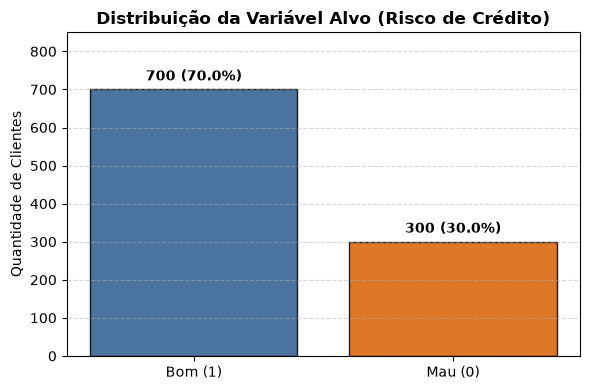

In [16]:
target_counts = df['class_label'].value_counts()
print(target_counts)
print("\nProporções:")
print(df['class_label'].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
bars = plt.bar(target_counts.index, target_counts.values, color=['#2b5c8f', '#d95f02'], edgecolor='black', alpha=0.85)
plt.title("Distribuição da Variável Alvo (Risco de Crédito)", fontsize=12, fontweight="bold")
plt.ylabel("Quantidade de Clientes")
plt.ylim(0, 850)
for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df)) * 100
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 15, f"{yval} ({pct:.1f}%)", ha="center", va="bottom", fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "eda_target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Análise dos Atributos Numéricos
Apresentamos as estatísticas descritivas (média, desvio padrão, mínimo, mediana e máximo) e as distribuições das 7 variáveis numéricas.

In [17]:
num_stats = df[NUMERICAL_COLS].describe().T
num_stats[['mean', 'std', 'min', '50%', 'max']]

,mean,std,min,50%,max
duration,20.903,12.058814,4.0,18.0,72.0
amount,3271.258,2822.736876,250.0,2319.5,18424.0
installment_rate,2.973,1.118715,1.0,3.0,4.0
residence_since,2.845,1.103718,1.0,3.0,4.0
age,35.546,11.375469,19.0,33.0,75.0
existing_credits_count_curr_bank,1.407,0.577654,1.0,1.0,4.0
dependent_count,1.155,0.362086,1.0,1.0,2.0


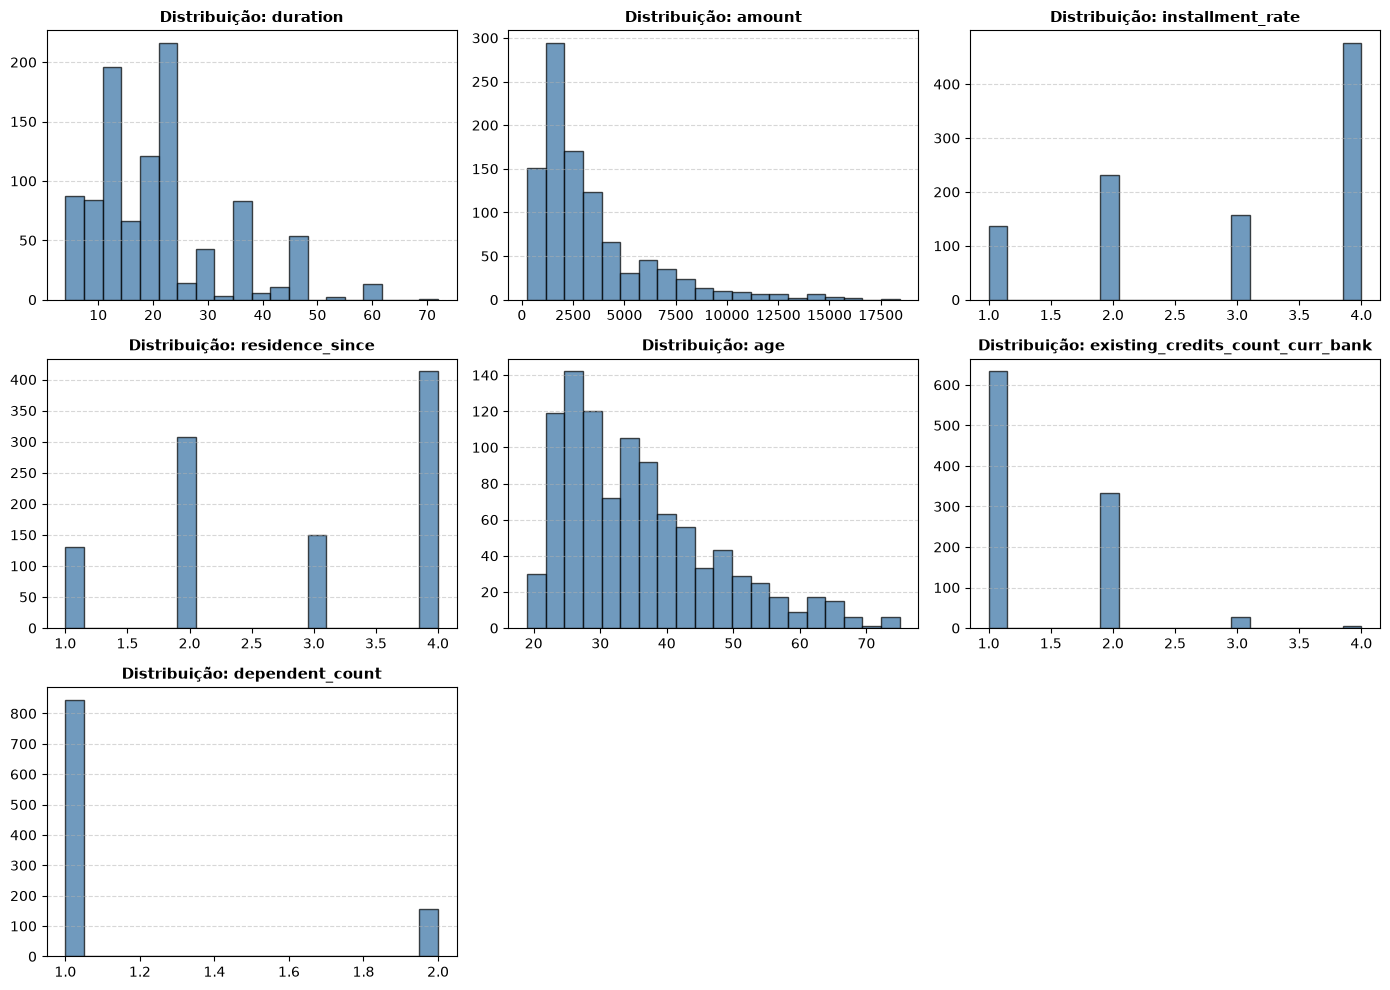

In [18]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()
for idx, col in enumerate(NUMERICAL_COLS):
    axes[idx].hist(df[col], bins=20, color="#3470a3", edgecolor="black", alpha=0.7)
    axes[idx].set_title(f"Distribuição: {col}", fontsize=11, fontweight="bold")
    axes[idx].grid(axis="y", linestyle="--", alpha=0.5)
fig.delaxes(axes[7])
fig.delaxes(axes[8])
plt.tight_layout()
plt.savefig(FIGURES_PATH / "eda_numerical_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

### Boxplots: Comparação entre Bons e Maus Pagadores
Analisamos como as principais variáveis numéricas variam de acordo com o risco de crédito.

- É possível notar que bons pagadores costumam fazer empréstimos menos duradouros e com valores menores que os maus pagadores, apesar de que existem outliers para essa tendência.
- Também percebe-se que os bons pagadores têm em sua maioria uma idade maior que os maus pagadores, e por fim, o `installment_rate` mostra quanto da renda do cliente está comprometida pelo empréstimo, e os bons pagadores demonstraram ter menor parte da renda direcionada para o pagamento de crédito em comparação aos maus pagadores.

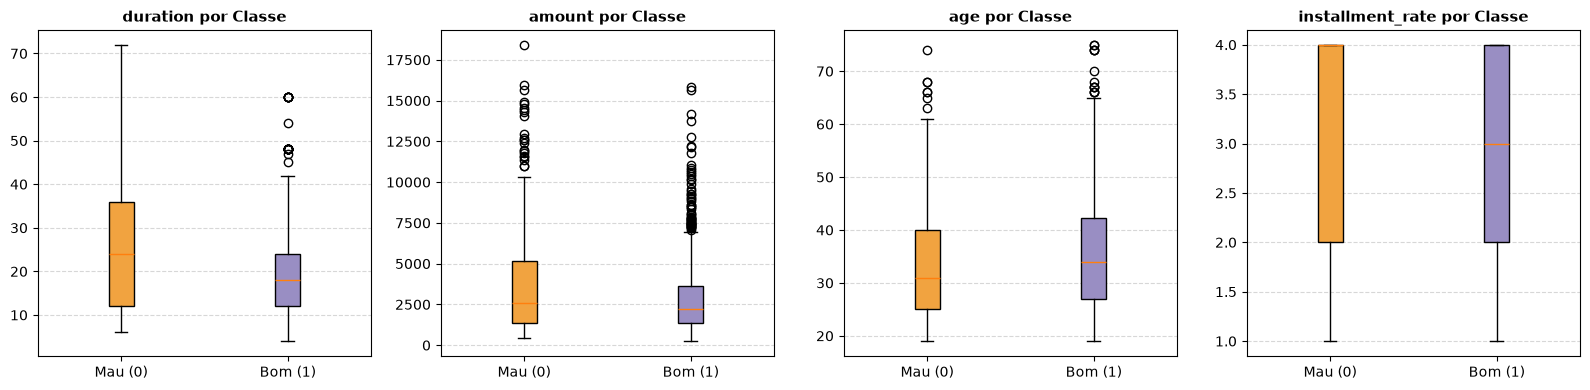

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
key_num = ["duration", "amount", "age", "installment_rate"]
for idx, col in enumerate(key_num):
    data_good = df[df["target"] == 1][col]
    data_bad = df[df["target"] == 0][col]
    bp = axes[idx].boxplot([data_bad, data_good], tick_labels=["Mau (0)", "Bom (1)"], patch_artist=True)
    bp['boxes'][0].set_facecolor("#f1a340")
    bp['boxes'][1].set_facecolor("#998ec3")
    axes[idx].set_title(f"{col} por Classe", fontsize=11, fontweight="bold")
    axes[idx].grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "eda_numerical_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

### Matriz de Correlação Linear (Pearson)
Verificamos o grau de colinearidade entre os preditores contínuos.

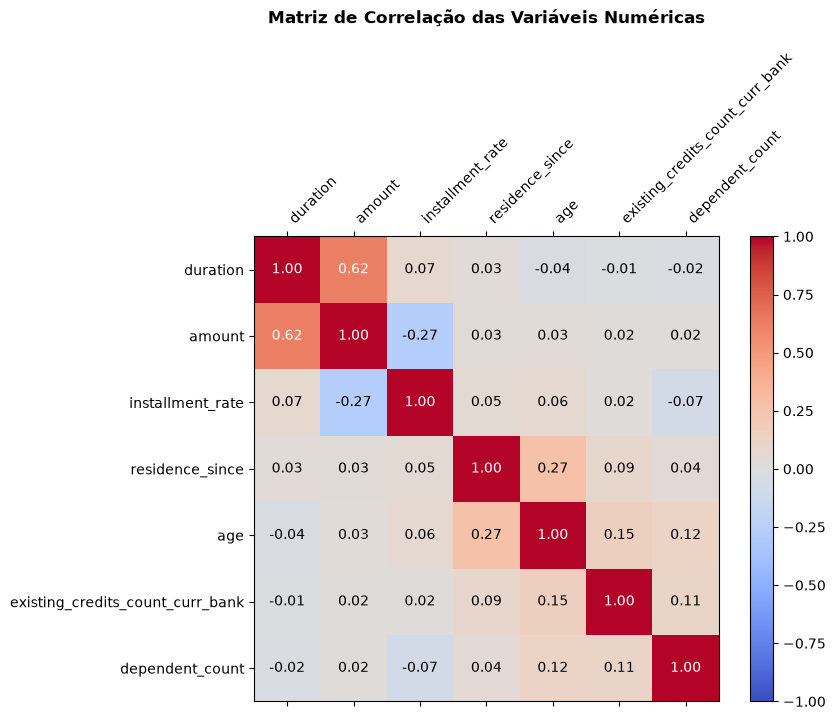

In [20]:
corr = df[NUMERICAL_COLS].corr()
plt.figure(figsize=(8, 6))
plt.matshow(corr, cmap="coolwarm", vmin=-1, vmax=1, fignum=1)
plt.colorbar()
plt.xticks(range(len(NUMERICAL_COLS)), NUMERICAL_COLS, rotation=45, ha="left")
plt.yticks(range(len(NUMERICAL_COLS)), NUMERICAL_COLS)
for i in range(len(NUMERICAL_COLS)):
    for j in range(len(NUMERICAL_COLS)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="black" if abs(corr.iloc[i, j]) < 0.6 else "white")
plt.title("Matriz de Correlação das Variáveis Numéricas", fontsize=12, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "eda_correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Análise dos Atributos Categóricos Mais Relevantes
Examinamos variáveis qualitativas com forte impacto intuitivo no risco bancário:
- `checking_status` (Situação da conta corrente)
- `credit_history` (Histórico de crédito prévio)
- `savings_account` (Poupança e reservas financeiras)
- `housing` (Situação de moradia: própria, alugada ou de favor)

Nos gráficos gerados abaixo, é possível perceber que:
- Conforme a quantidade de dinheiro na conta aumenta, mais confiável se torna o cliente. Entretanto, há um ponto contra-intuitivo: pessoas sem conta corrente nesse banco são as mais confiáveis. Numa primeira análise, esse quesito parece não fazer sentido, mas é explicado por existirem clientes com contas em outros bancos, outras fontes de renda, e por isso elas não são dependentes dessa instituição, mas ainda assim possuem segurança financeira.
- O `credit_history` também possui características "estranhas" à primeira vista, uma vez que pessoas que já fizeram empréstimo várias vezes aparentam ser mais arriscadas que as pessoas que nunca pegaram um empréstimo antes. Contudo, isso pode ser explicado pelo fato de que, pela pessoa nunca ter requisitado crédito antes, o banco não tem nenhum conhecimento sobre o histórico da pessoa. Já para as pessoas que tem empréstimos nesse ou em outros bancos, o banco consegue ter uma garantia que o cliente conseguiu se organizar e pagar por essas dívidas. 

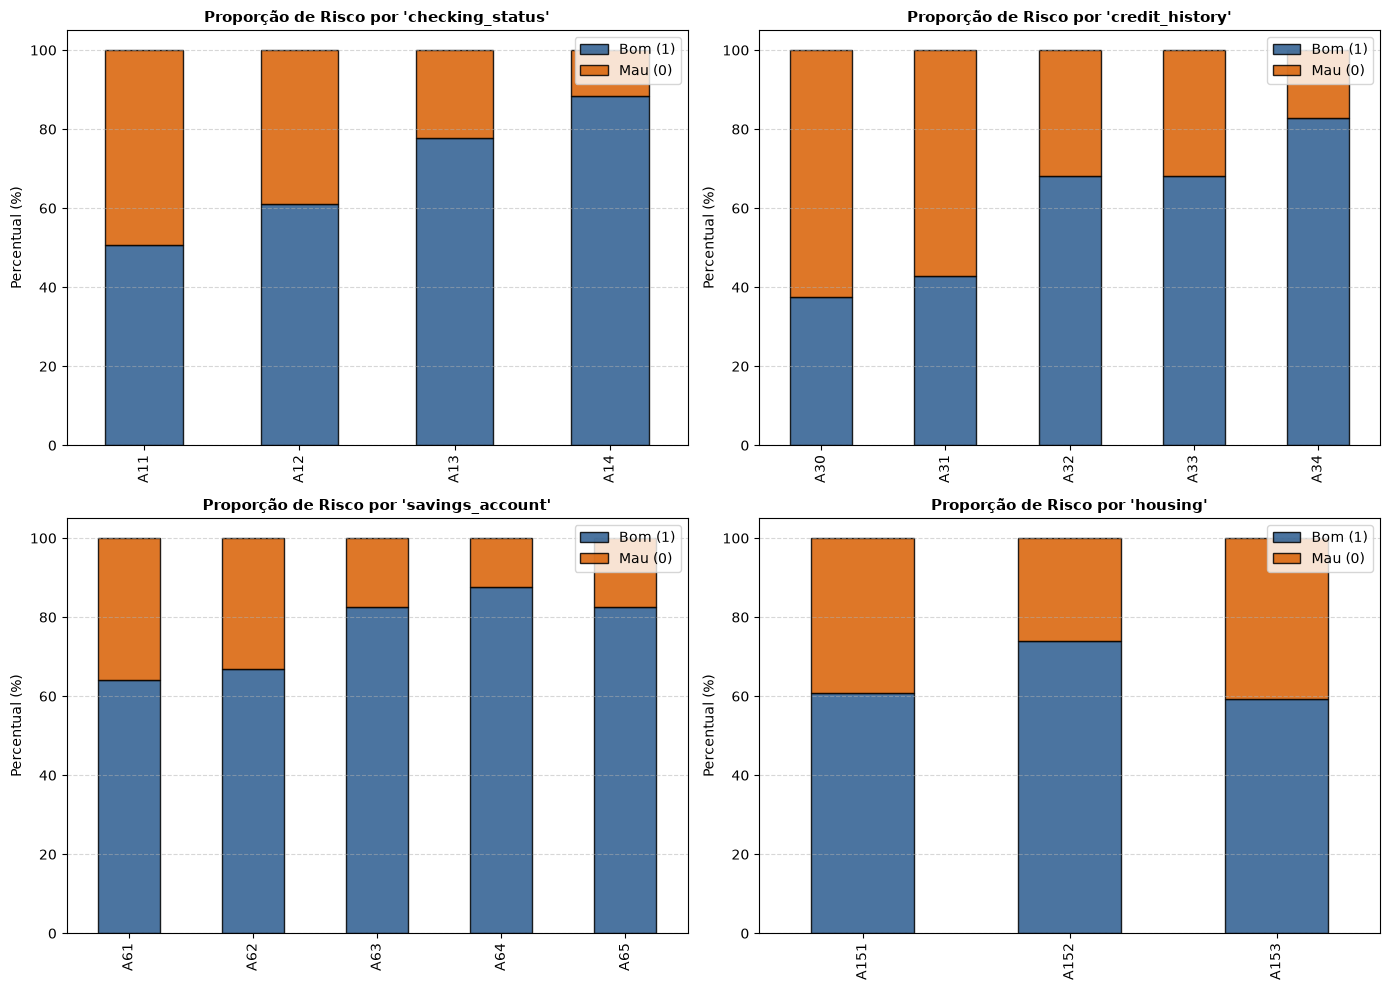

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
cat_inspect = ["checking_status", "credit_history", "savings_account", "housing"]

for idx, col in enumerate(cat_inspect):
    cross_tab = pd.crosstab(df[col], df["class_label"], normalize="index") * 100
    cross_tab[["Bom (1)", "Mau (0)"]].plot(kind="bar", stacked=True, ax=axes[idx], color=["#2b5c8f", "#d95f02"], alpha=0.85, edgecolor="black")
    axes[idx].set_title(f"Proporção de Risco por '{col}'", fontsize=11, fontweight="bold")
    axes[idx].set_ylabel("Percentual (%)")
    axes[idx].set_xlabel("")
    axes[idx].grid(axis="y", linestyle="--", alpha=0.5)
    axes[idx].legend(["Bom (1)", "Mau (0)"], loc="upper right")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "eda_categorical_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Valores Extremos (Outliers)
Quantificamos os valores extremos pelo critério do intervalo interquartil (IQR): são considerados extremos os valores fora de $[Q_1 - 1{,}5\,\text{IQR},\; Q_3 + 1{,}5\,\text{IQR}]$. A tabela também traz a assimetria (*skewness*) de cada atributo e, para `amount`, a taxa de maus pagadores entre os valores extremos, para verificar se eles são ruído ou informação relevante para o risco.

**Atenção:** em atributos discretos com poucos valores distintos (ex.: `dependent_count`, em que $Q_1 = Q_3 = 1$ e o IQR é zero), o critério marca como extremo qualquer valor diferente da moda e, por isso, não é informativo. A análise de valores extremos faz sentido principalmente para `amount`, `duration` e `age`.

In [22]:
def limites_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

linhas = []
for col in NUMERICAL_COLS:
    s = df[col]
    lo, hi = limites_iqr(s)
    mask = (s < lo) | (s > hi)
    linhas.append({
        "atributo": col,
        "outliers_IQR": int(mask.sum()),
        "outliers_%": round(100 * mask.mean(), 1),
        "limite_inferior": round(lo, 2),
        "limite_superior": round(hi, 2),
        "maximo": s.max(),
        "assimetria": round(s.skew(), 2),
    })
df_outliers = pd.DataFrame(linhas)
df_outliers.to_csv(TABLES_PATH / "eda_outliers.csv", index=False)
display(df_outliers)

# Os valores extremos de 'amount' são ruído ou carregam informação de risco?
lo, hi = limites_iqr(df["amount"])
extremo = (df["amount"] < lo) | (df["amount"] > hi)
taxa_maus_extremos = 100 * (df.loc[extremo, "target"] == 0).mean()
taxa_maus_demais = 100 * (df.loc[~extremo, "target"] == 0).mean()
print(f"'amount': limite superior (IQR) = DM {hi:,.0f}".replace(",", ".") + f"; {extremo.sum()} registros acima ({100*extremo.mean():.1f}%)")
print(f"Taxa de maus pagadores entre os extremos: {taxa_maus_extremos:.1f}% | nos demais: {taxa_maus_demais:.1f}%")

,atributo,outliers_IQR,outliers_%,limite_inferior,limite_superior,maximo,assimetria
0,duration,70,7.0,-6.00,42.00,72,1.09
1,amount,72,7.2,-2544.62,7882.38,18424,1.95
2,installment_rate,0,0.0,-1.00,7.00,4,-0.53
3,residence_since,0,0.0,-1.00,7.00,4,-0.27
4,age,23,2.3,4.50,64.50,75,1.02
5,existing_credits_count_curr_bank,6,0.6,-0.50,3.50,4,1.27
6,dependent_count,155,15.5,1.00,1.00,2,1.91


'amount': limite superior (IQR) = DM 7.882; 72 registros acima (7.2%)
Taxa de maus pagadores entre os extremos: 54.2% | nos demais: 28.1%


## 6. Resumo de Todos os Atributos Categóricos
A Seção 4 detalha quatro atributos. Aqui resumimos os 13: número de categorias, categoria dominante, categorias raras (< 5% das observações), taxa de maus pagadores nas categorias extremas e a associação com o alvo medida pelo **V de Cramér** (teste qui-quadrado de independência; $V \in [0,1]$).

,atributo,n_categorias,categoria_dominante,dominante_%,categorias_raras(<5%),menor_%_maus,categoria_menor_%_maus,maior_%_maus,categoria_maior_%_maus,cramers_v
0,checking_status,4,A14,39.4,0,11.7,A14,49.3,A11,0.352
1,credit_history,5,A32,53.0,2,17.1,A34,62.5,A30,0.248
2,savings_account,5,A61,60.3,1,12.5,A64,36.0,A61,0.190
3,purpose,10,A43,28.0,4,11.1,A48,44.0,A46,0.183
4,property,4,A123,33.2,0,21.3,A121,43.5,A124,0.154
5,employment_status,5,A73,33.9,0,22.4,A74,40.7,A72,0.136
6,housing,3,A152,71.3,0,26.1,A152,40.7,A153,0.135
7,other_installments,3,A143,81.4,1,27.5,A143,41.0,A141,0.113
8,sex_and_marital_status,4,A93,54.8,0,26.6,A93,40.0,A91,0.098
9,other_debtors,3,A101,90.7,1,19.2,A103,43.9,A102,0.082


Atributos com associação significativa ao alvo (p < 0,05): 11 de 13


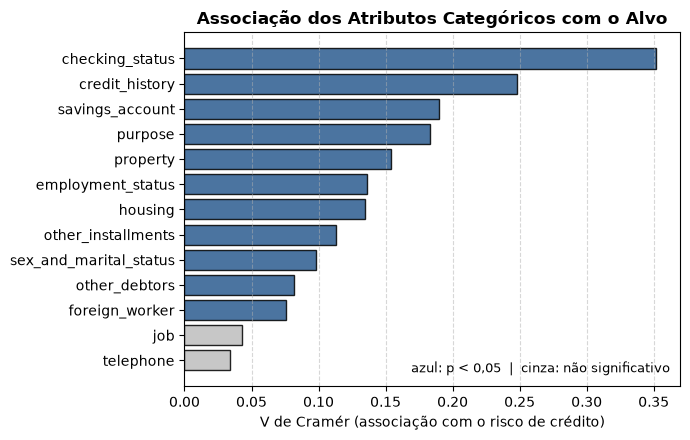

In [23]:
from scipy.stats import chi2_contingency

linhas, niveis = [], []
for col in CATEGORICAL_COLS:
    ct = pd.crosstab(df[col], df["target"])          # colunas: 0 (mau) e 1 (bom)
    chi2, p, _, _ = chi2_contingency(ct)
    n = ct.values.sum()
    v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    freq = df[col].value_counts(normalize=True)
    taxa_maus = 100 * ct[0] / ct.sum(axis=1)
    linhas.append({
        "atributo": col,
        "n_categorias": df[col].nunique(),
        "categoria_dominante": freq.index[0],
        "dominante_%": round(100 * freq.iloc[0], 1),
        "categorias_raras(<5%)": int((freq < 0.05).sum()),
        "menor_%_maus": round(taxa_maus.min(), 1),
        "categoria_menor_%_maus": taxa_maus.idxmin(),
        "maior_%_maus": round(taxa_maus.max(), 1),
        "categoria_maior_%_maus": taxa_maus.idxmax(),
        "cramers_v": round(v, 3),
        "p_valor": p,
    })
    for cat in ct.index:
        niveis.append({"atributo": col, "categoria": cat, "n": int(ct.loc[cat].sum()),
                       "%_base": round(100 * ct.loc[cat].sum() / n, 1),
                       "%_maus": round(taxa_maus[cat], 1)})

df_cat = pd.DataFrame(linhas).sort_values("cramers_v", ascending=False).reset_index(drop=True)
df_cat.to_csv(TABLES_PATH / "eda_categorical_summary.csv", index=False)
pd.DataFrame(niveis).to_csv(TABLES_PATH / "eda_categorical_levels.csv", index=False)
display(df_cat.drop(columns=["p_valor"]))
print(f"Atributos com associação significativa ao alvo (p < 0,05): {(df_cat['p_valor'] < 0.05).sum()} de {len(df_cat)}")

# Figura: força de associação de cada atributo categórico com o alvo
fig, ax = plt.subplots(figsize=(7, 4.5))
ordenado = df_cat.sort_values("cramers_v")
cores = ["#2b5c8f" if p < 0.05 else "#bdbdbd" for p in ordenado["p_valor"]]
ax.barh(ordenado["atributo"], ordenado["cramers_v"], color=cores, edgecolor="black", alpha=0.85)
ax.set_xlabel("V de Cramér (associação com o risco de crédito)")
ax.set_title("Associação dos Atributos Categóricos com o Alvo", fontsize=12, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.text(0.98, 0.04, "azul: p < 0,05  |  cinza: não significativo", transform=ax.transAxes, ha="right", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "eda_categorical_cramers_v.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Figura Consolidada para o Relatório
Figura de dois painéis usada na Seção 2.2 do relatório: (a) distribuição da variável alvo e (b) histograma de `amount`, com média, mediana e limite superior de valores extremos (IQR).

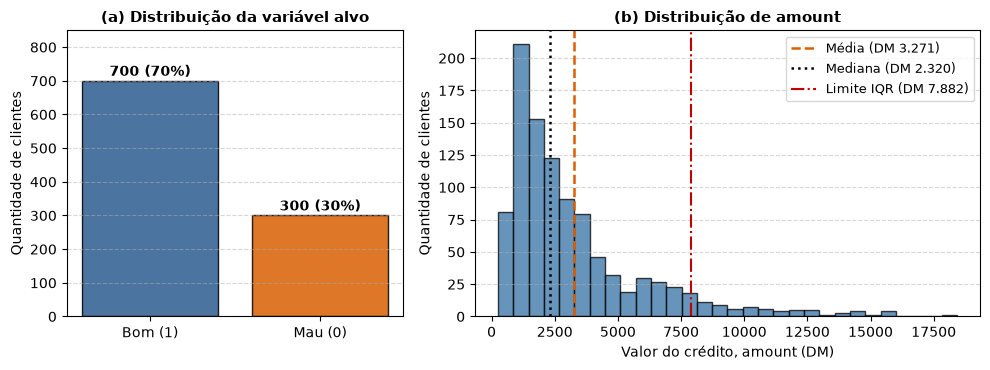

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 1.5]})

# (a) alvo
contagem = df["class_label"].value_counts()
barras = ax1.bar(contagem.index, contagem.values, color=["#2b5c8f", "#d95f02"], edgecolor="black", alpha=0.85)
ax1.set_ylim(0, 850)
ax1.set_ylabel("Quantidade de clientes")
ax1.set_title("(a) Distribuição da variável alvo", fontsize=11, fontweight="bold")
for b in barras:
    h = b.get_height()
    ax1.text(b.get_x() + b.get_width() / 2, h + 15, f"{int(h)} ({100*h/len(df):.0f}%)", ha="center", fontweight="bold")
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# (b) amount
_, lim_sup = limites_iqr(df["amount"])
br = lambda v: f"{v:,.0f}".replace(",", ".")      # 3271 -> 3.271 (padrão brasileiro)
ax2.hist(df["amount"], bins=30, color="#3470a3", edgecolor="black", alpha=0.75)
ax2.axvline(df["amount"].mean(), color="#d95f02", linestyle="--", linewidth=1.8, label=f"Média (DM {br(df['amount'].mean())})")
ax2.axvline(df["amount"].median(), color="black", linestyle=":", linewidth=1.8, label=f"Mediana (DM {br(df['amount'].median())})")
ax2.axvline(lim_sup, color="#c00000", linestyle="-.", linewidth=1.5, label=f"Limite IQR (DM {br(lim_sup)})")
ax2.set_xlabel("Valor do crédito, amount (DM)")
ax2.set_ylabel("Quantidade de clientes")
ax2.set_title("(b) Distribuição de amount", fontsize=11, fontweight="bold")
ax2.legend(fontsize=9)
ax2.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(FIGURES_PATH / "eda_distribuicoes.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Experimento: Efeito do Escalonamento em KNN e SVM
Para sustentar com evidência a discussão sobre pré-processamento (item *c* do enunciado), comparamos KNN e SVM **com** e **sem** `StandardScaler`, mantendo idênticos: partição treino/teste (`data/processed`), validação cruzada estratificada de 5 dobras, `random_state=42` e a codificação *one-hot*. Só o escalonamento das colunas numéricas muda (`passthrough` no lugar do `StandardScaler`).

- **Controlado** (padrão): hiperparâmetros fixos, lidos de `results/tables/best_hyperparameters.json`. Isola o efeito do escalonamento.
- **Reajustado** (opcional, `REAJUSTAR = True`): refaz o `GridSearchCV` completo em cada variante (melhor modelo com vs. sem escalonamento). Pode demorar bastante no SVM sem escalonamento, pois o kernel linear converge muito devagar com atributos em escalas diferentes.

O conjunto de teste é usado apenas para **relatar** as configurações já definidas; nenhuma escolha é feita sobre ele.

**Pré-requisito:** rodar `./run.sh all` antes (gera `data/processed/*.csv` e `results/tables/best_hyperparameters.json` e `metrics_test.csv`).

In [25]:
import sys, time, json, warnings
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
warnings.filterwarnings("ignore")

sys.path.append(str(BASE_PATH / "src" / "supervised"))
from train_models import get_knn, get_svm, RANDOM_STATE

REAJUSTAR = False   # True: refaz o GridSearchCV completo em cada variante (lento no SVM sem escalonamento)

train_df = pd.read_csv(PROCESSED_PATH / "train.csv")
test_df = pd.read_csv(PROCESSED_PATH / "test.csv")
X_tr, y_tr = train_df.drop(columns="class"), train_df["class"]
X_te, y_te = test_df.drop(columns="class"), test_df["class"]
melhores = json.load(open(TABLES_PATH / "best_hyperparameters.json", encoding="utf-8"))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"f1_macro": "f1_macro", "roc_auc": "roc_auc"}

def relatar_teste(modelo):
    pred = modelo.predict(X_te)
    proba = modelo.predict_proba(X_te)[:, 1]
    cm = confusion_matrix(y_te, pred, labels=[1, 0])      # linhas: real (bom, mau); colunas: previsto
    return {
        "Accuracy_Test": accuracy_score(y_te, pred),
        "Precision_Macro_Test": precision_score(y_te, pred, average="macro", zero_division=0),
        "Recall_Macro_Test": recall_score(y_te, pred, average="macro", zero_division=0),
        "F1_Macro_Test": f1_score(y_te, pred, average="macro", zero_division=0),
        "ROC_AUC_Test": roc_auc_score(y_te, proba),
        "Maus_detectados(de 60)": int(cm[1, 1]),
        "Falsos_positivos": int(cm[1, 0]),
    }

registros = []
modos = ["Controlado"] + (["Reajustado"] if REAJUSTAR else [])
for nome, construtor in [("KNN", get_knn), ("SVM", get_svm)]:
    for modo in modos:
        for escalonar in (True, False):
            pipe, grade = construtor()
            if not escalonar:
                pipe.set_params(preprocessor__num="passthrough")   # sem StandardScaler nas numéricas
            t0 = time.time()
            if modo == "Controlado":
                pipe.set_params(**melhores[nome])
                res = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring=scoring)
                f1_cv, f1_cv_std = res["test_f1_macro"].mean(), res["test_f1_macro"].std()
                pipe.fit(X_tr, y_tr)
                modelo, params = pipe, melhores[nome]
            else:
                gs = GridSearchCV(pipe, grade, cv=cv, scoring=scoring, refit="f1_macro").fit(X_tr, y_tr)
                i = gs.best_index_
                f1_cv, f1_cv_std = gs.cv_results_["mean_test_f1_macro"][i], gs.cv_results_["std_test_f1_macro"][i]
                modelo, params = gs.best_estimator_, gs.best_params_
            linha = {"Modo": modo, "Modelo": nome, "Escalonamento": "Sim" if escalonar else "Não",
                     "F1_Macro_CV_Mean": f1_cv, "F1_Macro_CV_Std": f1_cv_std,
                     **relatar_teste(modelo),
                     "Hiperparametros": json.dumps(params, ensure_ascii=False), "Tempo_s": round(time.time() - t0, 1)}
            registros.append(linha)
            print(f"{modo:10s} {nome:3s} escalonamento={linha['Escalonamento']:3s} "
                  f"F1(CV)={f1_cv:.3f}  F1(teste)={linha['F1_Macro_Test']:.3f}  AUC(teste)={linha['ROC_AUC_Test']:.3f}  "
                  f"({linha['Tempo_s']}s)")

df_escala = pd.DataFrame(registros)
df_escala.to_csv(TABLES_PATH / "scaling_experiment.csv", index=False)
cols = ["Modo", "Modelo", "Escalonamento", "F1_Macro_CV_Mean", "Accuracy_Test", "F1_Macro_Test",
        "ROC_AUC_Test", "Maus_detectados(de 60)", "Falsos_positivos"]
display(df_escala[cols].round(3))

Controlado KNN escalonamento=Sim F1(CV)=0.648  F1(teste)=0.620  AUC(teste)=0.673  (0.7s)
Controlado KNN escalonamento=Não F1(CV)=0.503  F1(teste)=0.560  AUC(teste)=0.588  (0.5s)
Controlado SVM escalonamento=Sim F1(CV)=0.699  F1(teste)=0.649  AUC(teste)=0.737  (1.5s)
Controlado SVM escalonamento=Não F1(CV)=0.450  F1(teste)=0.515  AUC(teste)=0.579  (1.9s)


,Modo,Modelo,Escalonamento,F1_Macro_CV_Mean,Accuracy_Test,F1_Macro_Test,ROC_AUC_Test,Maus_detectados(de 60),Falsos_positivos
0,Controlado,KNN,Sim,0.648,0.725,0.620,0.673,20,40
1,Controlado,KNN,Não,0.503,0.655,0.560,0.588,19,41
2,Controlado,SVM,Sim,0.699,0.720,0.649,0.737,27,33
3,Controlado,SVM,Não,0.450,0.720,0.515,0.579,7,53


Reprodutibilidade: variante com escalonamento idêntica a metrics_test.csv


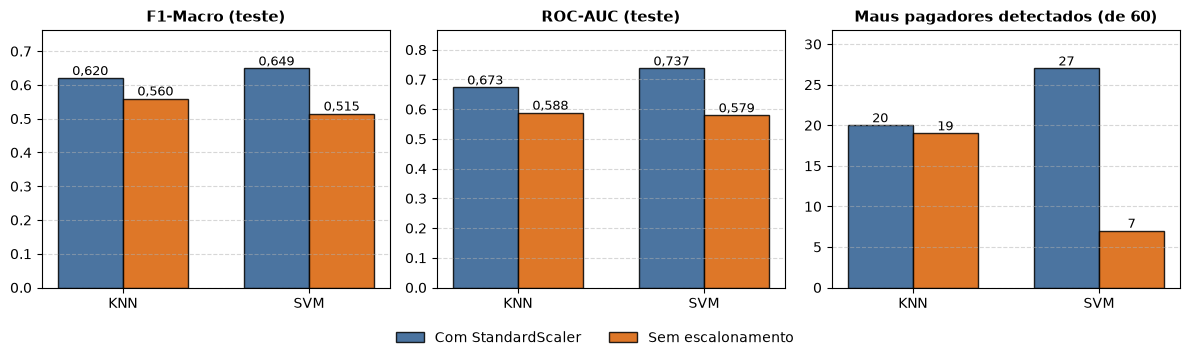

In [26]:
# Conferência de reprodutibilidade: a variante "com escalonamento" deve reproduzir metrics_test.csv
ref = pd.read_csv(TABLES_PATH / "metrics_test.csv").set_index("Modelo")
ok = True
for nome in ["KNN", "SVM"]:
    linha = df_escala[(df_escala["Modo"] == "Controlado") & (df_escala["Modelo"] == nome) & (df_escala["Escalonamento"] == "Sim")].iloc[0]
    for m_nb, m_ref in [("F1_Macro_Test", "F1_Macro_Test"), ("ROC_AUC_Test", "ROC_AUC_Test"), ("Accuracy_Test", "Accuracy_Test")]:
        if abs(linha[m_nb] - ref.loc[nome, m_ref]) > 1e-9:
            ok = False
            print(f"DIVERGE {nome} {m_nb}: notebook={linha[m_nb]:.4f} vs metrics_test.csv={ref.loc[nome, m_ref]:.4f}")
print("Reprodutibilidade: variante com escalonamento idêntica a metrics_test.csv" if ok else "Atenção: rode evaluate.py novamente (metrics_test.csv desatualizado).")

# Figura: efeito do escalonamento (experimento controlado)
ctrl = df_escala[df_escala["Modo"] == "Controlado"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (metrica, rotulo) in zip(axes, [("F1_Macro_Test", "F1-Macro (teste)"), ("ROC_AUC_Test", "ROC-AUC (teste)"), ("Maus_detectados(de 60)", "Maus pagadores detectados (de 60)")]):
    x = np.arange(2)
    for k, (esc, cor) in enumerate([("Sim", "#2b5c8f"), ("Não", "#d95f02")]):
        vals = [ctrl[(ctrl["Modelo"] == m) & (ctrl["Escalonamento"] == esc)][metrica].iloc[0] for m in ["KNN", "SVM"]]
        barras = ax.bar(x + (k - 0.5) * 0.35, vals, 0.35, color=cor, edgecolor="black", alpha=0.85,
                        label="Com StandardScaler" if esc == "Sim" else "Sem escalonamento")
        for b, v in zip(barras, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}".replace(".", ",") if v < 1.5 else f"{int(v)}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x, ["KNN", "SVM"])
    ax.set_title(rotulo, fontsize=11, fontweight="bold")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
handles, rotulos = axes[0].get_legend_handles_labels()
fig.legend(handles, rotulos, loc="lower center", ncol=2, fontsize=10, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig(FIGURES_PATH / "scaling_experiment.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Conclusões da EDA e Justificativas de Pré-Processamento

Com base nas evidências obtidas nesta análise exploratória, fundamentamos as decisões adotadas no arquivo `preprocess.py` e nos modelos de `train_models.py`:

1. **Escalonamento Padronizado (`StandardScaler`):**
   - As variáveis numéricas apresentam ordens de grandeza completamente distintas: `amount` atinge até 18.424 marcos alemães com desvio padrão de 2.822, enquanto `installment_rate` varia apenas de 1 a 4 e `duration` de 4 a 72 meses.
   - Algoritmos baseados em distância (como **KNN**) e otimização geométrica de margem (**SVM**) seriam desproporcionalmente dominados pelo atributo `amount` caso não houvesse padronização $(\mu=0, \sigma=1)$.
   - A Seção 8 quantifica esse efeito: sem o `StandardScaler`, o desempenho do KNN e do SVM no teste cai de forma acentuada (ver `results/tables/scaling_experiment.csv`).

2. **Codificação One-Hot (`OneHotEncoder`):**
   - As 13 variáveis categóricas contêm categorias qualitativas (ex.: finalidade do empréstimo `purpose`, moradia `housing`, tipo de emprego `job`).
   - Aplicar uma codificação ordinal (1, 2, 3...) introduziria relações de magnitude arbitrárias e espúrias (ex.: assumir que 'carro novo' é menor que 'reparos'). A codificação One-Hot gera representações binárias ortogonais, evitando distorções.
   - O parâmetro `handle_unknown='ignore'` assegura robustez caso surjam categorias não observadas nos folds de treino.

3. **Estratégia de Validação Cruzada Estratificada (`StratifiedKFold`):**
   - Como a base apresenta desbalanceamento moderado de 70% bons e 30% maus pagadores, a divisão estratificada em 5 folds garante que cada partição de treino e validação mantenha a proporção exata de classes, evitando folds com sub-representação da classe de risco.

4. **Tratamento de Dados Ausentes e Outliers:**
   - A base é íntegra e não possui valores ausentes.
   - Valores extremos em `amount` e `duration` representam operações de crédito atípicas, mas perfeitamente legítimas no contexto bancário, motivo pelo qual foram preservados para permitir que modelos como Random Forest e Árvore de Decisão capturem essas regras de fronteira. A Seção 5 quantifica esses valores extremos (critério do IQR) e mostra sua taxa de inadimplência, evidência de que carregam informação de risco e não ruído.
